# Лабораторная работа по прикладной статистике

## Оглавление
- [0. Введение](#section0)
  - [0.1 ](#section0_1)
- [1. Lab01 - sprint 1](#section1)
  - [1.1 Подготовка данных](#section1_1)
  - [1.7 Lab resume](#section1_7)
  - [1.8 cat_mark_table](#section1_8)
- [2. Lab01 - sprint 2](#section2)
  - [2.7 Lab resume](#section2_7)
  - [2.8 cat_mark_table](#section2_8)
- [3. Выводы](#section3)

## <a id="section0"></a>Введение

## <a id="section1"></a>1. Lab01 - sprint 1
### <a id="section1_1"></a>1.1 Подготовка данных

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.1)

In [7]:
water_2018 = pd.read_csv('data/water/ground_water_quality_2018_post.csv')
water_2019 = pd.read_csv('data/water/ground_water_quality_2019_post.csv')
water_2020 = pd.read_csv('data/water/ground_water_quality_2020_post.csv')

print("2018:", water_2018.shape)
print("2019:", water_2019.shape)
print("2020:", water_2020.shape)

weather = pd.read_csv('data/weather/combined_output.csv')
print("Weather:", weather.shape)

2018: (374, 26)
2019: (364, 26)
2020: (368, 27)
Weather: (1084267, 10)


In [35]:
rename_dict_2019 = {
    'EC': 'E.C',
    'CO_-2': 'CO3',
    'HCO_ - ': 'HCO3',
    'Cl -': 'Cl',
    'F -': 'F',
    'Na+': 'Na',
    'Ca+2': 'Ca',
    'Mg+2': 'Mg'
}

water_2019 = water_2019.rename(columns=rename_dict_2019)

if 'Unnamed: 8' in water_2020.columns:
    water_2020 = water_2020.drop(columns=['Unnamed: 8'])

In [41]:
display(water_2018.head())
display(water_2018[['TDS', 'F', 'E.C', 'Ca', 'Mg', 'Na', 'Cl', 'HCO3', 'pH']].info())
display(water_2018[['TDS', 'F', 'E.C', 'Ca', 'Mg', 'Na', 'Cl', 'HCO3', 'pH']].describe())
display(water_2018[['TDS', 'F', 'E.C', 'Ca', 'Mg', 'Na', 'Cl', 'HCO3', 'pH']].isnull().sum())

display(water_2019.head())
display(water_2019[['TDS', 'F', 'E.C', 'Ca', 'Mg', 'Na', 'Cl', 'HCO3', 'pH']].info())
display(water_2019[['TDS', 'F', 'E.C', 'Ca', 'Mg', 'Na', 'Cl', 'HCO3', 'pH']].describe())
display(water_2019[['TDS', 'F', 'E.C', 'Ca', 'Mg', 'Na', 'Cl', 'HCO3', 'pH']].isnull().sum())

display(water_2020.head())
display(water_2020[['TDS', 'F', 'E.C', 'Ca', 'Mg', 'Na', 'Cl', 'HCO3', 'pH']].info())
display(water_2020[['TDS', 'F', 'E.C', 'Ca', 'Mg', 'Na', 'Cl', 'HCO3', 'pH']].describe())
display(water_2020[['TDS', 'F', 'E.C', 'Ca', 'Mg', 'Na', 'Cl', 'HCO3', 'pH']].isnull().sum())

display(weather.head())
display(weather.info())
display(weather.describe())
display(weather.isnull().sum())

,sno,district,mandal,village,lat_gis,long_gis,gwl,season,pH,E.C,TDS,CO3,HCO3,Cl,F,NO3,SO4,Na,K,Ca,Mg,T.H,SAR,Classification,RSC meq / L,Classification.1
0,1,ADILABAD,Adilabad,Adilabad,19.668300,78.524700,5.09,postmonsoon 2018,8.28,745,476.80,0,220.0,60,0.44,42.276818,46.0,49.0,4.0,48,38.896,279.934211,1.273328,C2S1,-1.198684,P.S.
1,2,ADILABAD,Bazarhatnur,Bazarhatnur,19.458888,78.350833,5.10,postmonsoon 2018,8.29,921,589.44,0,230.0,80,0.56,100.659091,68.0,42.0,5.0,56,63.206,399.893092,0.913166,C3S1,-3.397862,P.S.
2,3,ADILABAD,Gudihatnoor,Gudihatnoor,19.525555,78.512222,4.98,postmonsoon 2018,7.69,510,326.40,0,200.0,30,0.66,41.471545,44.0,45.0,2.0,24,38.896,219.934211,1.319284,C2S1,-0.398684,P.S.
3,4,ADILABAD,Jainath,Jainath,19.730555,78.640000,5.75,postmonsoon 2018,8.09,422,270.08,0,160.0,10,0.58,10.669864,35.0,27.0,1.0,32,19.448,159.967105,0.928155,C2S1,0.000658,P.S.
4,5,ADILABAD,Narnoor,Narnoor,19.495665,78.852654,2.15,postmonsoon 2018,8.21,2321,1485.44,0,300.0,340,2.56,128.843636,280.0,298.0,5.0,56,92.378,519.843750,5.682664,C4S2,-4.396875,P.S.


<class 'pandas.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   TDS     374 non-null    float64
 1   F       374 non-null    float64
 2   E.C     374 non-null    int64  
 3   Ca      374 non-null    int64  
 4   Mg      374 non-null    float64
 5   Na      374 non-null    float64
 6   Cl      374 non-null    int64  
 7   HCO3    374 non-null    float64
 8   pH      374 non-null    float64
dtypes: float64(6), int64(3)
memory usage: 26.4 KB


None

,TDS,F,E.C,Ca,Mg,Na,Cl,HCO3,pH
count,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000
mean,838.785027,1.237570,1310.601604,73.540107,50.480107,122.495842,187.005348,277.676970,7.893182
std,487.262064,0.824399,761.346975,55.003215,35.990466,103.606183,175.897896,125.746737,0.453799
min,135.680000,0.070000,212.000000,8.000000,4.862000,5.076154,10.000000,30.000000,6.600000
25%,490.400000,0.692250,766.250000,40.000000,24.310000,58.076763,60.000000,186.523010,7.580000
50%,751.040000,1.060000,1173.500000,56.000000,43.758000,96.697517,140.000000,263.842574,7.920000
75%,1066.400000,1.545000,1666.250000,96.000000,63.206000,153.622703,260.000000,353.548878,8.217500
max,3481.600000,4.970000,5440.000000,488.000000,228.514000,714.800195,1500.000000,970.588963,10.440000


TDS     0
F       0
E.C     0
Ca      0
Mg      0
Na      0
Cl      0
HCO3    0
pH      0
dtype: int64

,sno,district,mandal,village,lat_gis,long_gis,gwl,season,pH,E.C,TDS,CO_-2,HCO3,Cl,F,NO3-,SO4-2,Na,K,Ca,Mg,T.H,SAR,Classification,RSC meq / L,Classification.1
0,1,ADILABAD,Adilabad,Adilabad,19.668300,78.524700,6.45,post monsoon 2019,8.32,2355,1507.20,30.0,320,340,0.64,66.435000,377.0,273.0,113.0,80.0,82.654,539.860197,5.108509,C4S2,-3.797204,P.S.
1,2,ADILABAD,Bazarhatnur,Bazarhatnur,19.458888,78.350833,3.85,post monsoon 2019,8.30,565,361.60,20.0,180,40,2.21,38.049136,52.0,89.0,14.0,48.0,4.862,139.991776,3.196982,C2S1,1.200164,P.S.
2,3,ADILABAD,Gudihatnoor,Gudihatnoor,19.525555,78.512222,4.45,post monsoon 2019,8.12,766,490.24,0.0,190,20,0.55,41.270227,43.0,39.0,10.0,40.0,24.310,199.958882,1.199130,C3S1,-0.199178,P.S.
3,4,ADILABAD,Jainath,Jainath,19.730555,78.640000,3.95,post monsoon 2019,7.09,555,355.20,0.0,220,20,0.48,14.092273,31.0,40.0,5.0,40.0,24.310,199.958882,1.229877,C2S1,0.400822,P.S.
4,5,ADILABAD,Narnoor,Narnoor,19.495665,78.852654,2.15,post monsoon 2019,7.97,735,470.40,0.0,340,30,1.08,18.923909,28.0,44.0,16.0,72.0,34.034,319.942434,0.996598,C2S1,0.401151,P.S.


... (10 outputs left out)

<class 'pandas.DataFrame'>
RangeIndex: 1084267 entries, 0 to 1084266
Data columns (total 10 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   district        1084267 non-null  str    
 1   mandal          1084265 non-null  str    
 2   date            1084267 non-null  str    
 3   rainfall        1084267 non-null  float64
 4   temp_min        1084263 non-null  float64
 5   temp_max        1084263 non-null  float64
 6   humidity_min    1084214 non-null  float64
 7   humidity_max    1084218 non-null  float64
 8   wind_speed_min  1035149 non-null  float64
 9   wind_speed_max  1070506 non-null  float64
dtypes: float64(7), str(3)
memory usage: 113.5 MB


None

,rainfall,temp_min,temp_max,humidity_min,humidity_max,wind_speed_min,wind_speed_max
count,1.084267e+06,1.084263e+06,1.084263e+06,1.084214e+06,1.084218e+06,1.035149e+06,1.070506e+06
mean,2.989913e+00,2.236683e+01,3.418970e+01,4.541993e+01,8.530201e+01,2.227572e-01,9.854651e+00
std,1.083671e+01,4.350849e+00,4.191834e+00,2.178450e+01,1.707400e+01,1.012684e+00,9.482388e+00
min,0.000000e+00,2.700000e+00,-1.000000e+00,-1.000000e+00,-1.000000e+00,-1.000000e+00,-1.000000e+00
25%,0.000000e+00,2.010000e+01,3.120000e+01,2.760000e+01,7.690000e+01,0.000000e+00,4.600000e+00
50%,0.000000e+00,2.320000e+01,3.380000e+01,4.360000e+01,9.105000e+01,0.000000e+00,8.500000e+00
75%,0.000000e+00,2.510000e+01,3.720000e+01,6.190000e+01,9.870000e+01,0.000000e+00,1.270000e+01
max,3.910000e+02,8.760000e+01,4.790000e+01,1.000000e+02,1.000000e+02,3.130000e+01,2.344000e+02


district              0
mandal                2
date                  0
rainfall              0
temp_min              4
temp_max              4
humidity_min         53
humidity_max         49
wind_speed_min    49118
wind_speed_max    13761
dtype: int64

### 1.1.1 Загрузка и структура данных воды

Данные успешно загружены. Размерности исходных датасетов:
- **Вода 2018:** 374 строки, 26 столбцов.
- **Вода 2019:** 364 строки, 26 столбцов.
- **Вода 2020:** 368 строк, 27 столбцов.

Для дальнейшего анализа из гидрохимических данных были выбраны 9 ключевых показателей: `TDS`, `F`, `E.C`, `Ca`, `Mg`, `Na`, `Cl`, `HCO3`, `pH`.
Проверка на пропуски (`isnull().sum()`) показала, что во всех трёх файлах по выбранным столбцам пропусков нет. 

Сводная таблица описательных статистик по годам.
| Год | N (строк) | TDS: mean | TDS: median | TDS: min | TDS: max | F: mean | F: median | F: min | F: max | pH: mean | pH: min | pH: max |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **2018** | 374 | 838.79 | 751.04 | 135.68 | 3481.60 | 1.238 | 1.060 | 0.070 | 4.970 | 7.89 | 6.60 | 10.44 |
| **2019** | 364 | 871.85 | 762.88 | 131.20 | 3558.40 | 1.094 | 0.925 | 0.040 | 4.610 | 7.81 | 6.11 | 9.10 |
| **2020** | 368 | 905.41 | 751.68 | 167.04 | 6079.36 | 1.017 | 0.840 | 0.043 | 7.700 | *str* | *str* | *str* |

#### Предварительные выводы по структуре данных:
1. В данных по воде в выбранных столбцах отсутствуют пропуски, что позволяет использовать всю выборку без искажений статистики.
2. Для TDS и F во всех трёх годах среднее значение (`mean`) больше медианы (`median`). Например, в 2018 году средний TDS = 838.79, а медиана = 751.04. Это показывает наличие ассиметрии и **лог-нормального распределения**, проверим это ниже.
3. В данных присутствуют особенно высокие значения TDS (максимум 6079.36 мг/л в 2020 году) и фторида (7.7 мг/л в 2020 году). Вероятно, это особенности гидрохимии местности, что может быть интересно в дальнейшем анализе. 
5. Медианный TDS держится примерно на одном уровне (~750-760 мг/л) при увеличении среднего заначения, в то время как медианный фторид плавно снижается с 1.06 (2018) до 0.84 (2020). Эту особенность также можно изучить.
6. В 2020 году столбец `pH` распознался как строка (`str`), тогда как в 2018 и 2019 это числа. Потребуется принудительная конвертация в числовой формат.

### 1.1.2 Загрузка и структура данных погоды

**Размерность:** 1 084 267 строк, 10 столбцов. Данные представлены в виде ежедневных наблюдений (Daily data) по мандалам (районам). 
**Ключи:** `district`, `mandal`, `date` (на данный момент тип `str`, требует конвертации в datetime).
**Метеопоказатели:** `rainfall`, `temp_min`, `temp_max`, `humidity_min`, `humidity_max`, `wind_speed_min`, `wind_speed_max`.

**Пропуски в данных:** 
- В ключевых для работы столбцах (`district`, `date`, `rainfall`) пропусков **нет**.
- В `mandal` пропущено 2 значения.
- В метеопоказателях есть пропуски: минимальные (4–53 значения) во влажности и температуре, и значительное количество в скорости ветра.

| Показатель | Пропуски (кол-во) | count | mean | std | min | 25% | 50% (median) | 75% | max |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **district** | 0 | 1 084 267 | - | - | - | - | - | - | - |
| **mandal** | 2 | 1 084 265 | - | - | - | - | - | - | - |
| **date** | 0 | 1 084 267 | - | - | - | - | - | - | - |
| **rainfall** | 0 | 1 084 267 | 2.99 | 10.83 | 0.0 | 0.0 | 0.0 | 0.0 | 391.0 |
| **temp_min** | 4 | 1 084 263 | 22.37 | 4.35 | -1.0 | 20.1 | 23.2 | 25.1 | 87.6 |
| **temp_max** | 4 | 1 084 263 | 34.19 | 4.19 | -1.0 | 31.2 | 33.8 | 37.2 | 47.9 |
| **humidity_min** | 53 | 1 084 214 | 45.42 | 21.78 | -1.0 | 27.6 | 43.6 | 61.9 | 100.0 |
| **humidity_max** | 49 | 1 084 218 | 85.30 | 17.07 | -1.0 | 76.9 | 91.05 | 98.7 | 100.0 |
| **wind_speed_min** | 49 118 | 1 035 149 | 0.22 | 1.01 | -1.0 | 0.0 | 0.0 | 0.0 | 31.3 |
| **wind_speed_max** | 13 761 | 1 070 506 | 9.85 | 9.48 | -1.0 | 4.6 | 8.5 | 12.7 | 234.4 |

#### Предварительные выводы по погодным данным:
1. Значения медианы и 75% равны 0. Это означает, что в Телангане большинство дней в году – сухие. Максимум осадков за день составил 391 мм. Также наблюдается ассиметрия.
2. В данных присутствуют физически невозможные значения:
   - Влажность (`humidity_min`, `humidity_max`) имеет минимум `-1.0` (влажность не может быть отрицательной).
   - Скорость ветра (`wind_speed_min`, `wind_speed_max`) имеет отрицательные значения `-1.0` и нереалистичный максимум `234.4` (вероятно, ошибка оборудования или сбой при кодировке данных).
   - Минимальная температура местами указана как `-1.0`, а максимальная температура `87.6°C`, что невозможно для Индии.
   Так как для проверки гипотезы используются только данные `rainfall`, эти аномалии можно пропустить и не удалять.
3. Для работы понадобится только столбец `rainfall`. Но также нужно обработать следующие данные:
   - Перевести столбец `date` в формат даты (datetime).
   - Отфильтровать только месяцы муссона (июнь–сентябрь).
   - Сгруппировать данные по `district`, `mandal` и году.

In [45]:
water_2020['pH'] = pd.to_numeric(water_2020['pH'], errors='coerce')
print("Тип данных pH (2020):", water_2020['pH'].dtype)

Тип данных pH (2020): float64


In [48]:
weather['date'] = pd.to_datetime(weather['date'], dayfirst=True, format='mixed')

print("Тип данных date:", weather['date'].dtype)
print("Первые 3 даты:", weather['date'].head(3).tolist())

Тип данных date: datetime64[us]
Первые 3 даты: [Timestamp('2018-01-01 00:00:00'), Timestamp('2018-01-02 00:00:00'), Timestamp('2018-01-03 00:00:00')]


In [58]:
weather['month'] = weather['date'].dt.month
monsoon_weather = weather[weather['month'].isin([6, 7, 8, 9])]

print("Строк до фильтрации:", len(weather))
print("Строк после фильтрации (только муссон):", len(monsoon_weather))

Строк до фильтрации: 1084267
Строк после фильтрации (только муссон): 393349


In [72]:
monsoon_weather = monsoon_weather.dropna(subset=['mandal'])

monsoon_weather['year'] = monsoon_weather['date'].dt.year

weather_agg = monsoon_weather.groupby(['district', 'mandal', 'year'])['rainfall'].sum().reset_index()

weather_agg = weather_agg.rename(columns={'rainfall': 'total_rainfall_mm'})

print("Размер таблицы с погодой после агрегации:", weather_agg.shape)
display(weather_agg.head())

Размер таблицы с погодой после агрегации: (3063, 4)


,district,mandal,year,total_rainfall_mm
0,Adilabad,Adilabad (Urban),2018,2242.6
1,Adilabad,Adilabad (Urban),2019,685.2
2,Adilabad,Adilabad Rural,2018,1067.7
3,Adilabad,Adilabad Rural,2019,944.9
4,Adilabad,Adilabad Rural,2020,883.9


In [73]:
water_all = pd.concat([water_2018, water_2019, water_2020], ignore_index=True)

water_all['year'] = water_all['season'].str.split().str[-1].astype(int)

water_agg = water_all.groupby(['district', 'mandal', 'year'])[['TDS', 'F', 'E.C', 'Ca', 'Mg', 'Na', 'Cl', 'HCO3', 'pH']].mean().reset_index()

print("Размер таблицы с водой после агрегации:", water_agg.shape)
display(water_agg.head())

Размер таблицы с водой после агрегации: (949, 12)


,district,mandal,year,TDS,F,E.C,Ca,Mg,Na,Cl,HCO3,pH
0,ADILABAD,Adilabad,2018,476.80,0.44,745.0,48.0,38.896,49.0,60.0,220.0,8.28
1,ADILABAD,Adilabad,2019,1507.20,0.64,2355.0,80.0,82.654,273.0,340.0,320.0,8.32
2,ADILABAD,Adilabad,2020,945.28,0.65,1477.0,24.0,72.930,171.0,220.0,390.0,8.01
3,ADILABAD,Bazarhatnur,2018,589.44,0.56,921.0,56.0,63.206,42.0,80.0,230.0,8.29
4,ADILABAD,Bazarhatnur,2019,361.60,2.21,565.0,48.0,4.862,89.0,40.0,180.0,8.30


In [75]:
districts_water = set(water_agg['district'].str.upper().str.strip())
districts_weather = set(weather_agg['district'].str.upper().str.strip())

print("Районы, которые есть в ВОДЕ, но нет в ПОГОДЕ:")
print(districts_water - districts_weather)
print("\nРайоны, которые есть в ПОГОДЕ, но нет в ВОДЕ:")
print(districts_weather - districts_water)

mandals_water = set(water_agg['mandal'].str.upper().str.strip())
mandals_weather = set(weather_agg['mandal'].str.upper().str.strip())

print("\nМандалы, которые есть в ВОДЕ, но нет в ПОГОДЕ:")
print(mandals_water - mandals_weather) 
print("\nМандалы, которые есть в ПОГОДЕ, но нет в ВОДЕ:")
print(mandals_weather - mandals_water) 

Районы, которые есть в ВОДЕ, но нет в ПОГОДЕ:
{'YADADRI', 'BHADRADRI', 'SIRCILLA', 'MEDCHAL', 'PEDDAPALLY', 'JOGULAMBA(GADWAL)', 'JAGITYAL', 'BHUPALPALLY'}

Районы, которые есть в ПОГОДЕ, но нет в ВОДЕ:
{'HANUMAKONDA', 'WARANGAL', 'PEDDAPALLI', 'JOGULAMBA GADWAL', 'YADADRI BHUVANAGIRI', 'MEDCHAL-MALKAJGIRI', 'JAYASHANKAR', 'JAYASHANKAR-BHUPALPALLY', 'BHADRADRI-KOTHAGUDEM', 'KUMURAM BHEEM - ASIFABAD', 'MULUG', 'WARANGAL URBAN', 'KOMARAM BHEEM-ASIFABAD', 'RAJANNA-SIRICILLA', 'JOGULAMBA-GADWAL', 'BHADRADRI KOTHAGUDEM', 'YADADRI-BHONGIR', 'WARANGAL RURAL', 'RAJANNA SIRCILLA', 'JAGTIAL'}

Мандалы, которые есть в ВОДЕ, но нет в ПОГОДЕ:
{'R.C.PURAM', 'AMARABAD', 'KORUTLA', 'YELLAREDDIPET', 'RAGHUNADHAPALLI', 'DHANTALAPALLY', 'NARKETPALLI', 'MARRIPEDA', 'BAZARHATNUR', 'MAHABUBNAGAR (R)', 'CC KUNTA', 'IEEZA', 'VAILPOOR', 'ETURU NAGARAM', 'K-T DODDI', 'JULURPADU', 'KHAMMAM(U)', 'SIDDIPET', 'PEDDAVOORA', 'ZAFERGAD', 'Y.GUTTA', 'YEDAPALLI', 'DARPALLY', 'YALAL', 'HATHNOORA', 'HASANPARTHI', 'CHENNAR

In [89]:
district_mapping = {
    'YADADRI BHUVANAGIRI': 'YADADRI',
    'YADADRI-BHONGIR': 'YADADRI',
    
    'BHADRADRI-KOTHAGUDEM': 'BHADRADRI',
    'BHADRADRI KOTHAGUDEM': 'BHADRADRI',

    'RAJANNA-SIRCILLA': 'SIRCILLA',
    'RAJANNA SIRCILLA': 'SIRCILLA',

    'MEDCHAL-MALKAJGIRI': 'MEDCHAL',
 
    'PEDDAPALLI': 'PEDDAPALLY',
    'JAGITAL': 'JAGITYAL',

    'JOGULAMBA GADWAL': 'JOGULAMBA(GADWAL)',
    'JOGULAMBA-GADWAL': 'JOGULAMBA(GADWAL)',

    'JAYASHANKAR-BHUPALPALLY': 'BHUPALPALLY',
    'JAYASHANKAR': 'BHUPALPALLY',
 
    'WARANGAL URBAN': 'WARANGAL',
    'WARANGAL RURAL': 'WARANGAL',
    'HANUMAKONDA': 'WARANGAL' ,

    'JAGTIAL': 'JAGITYAL',  
    'WARANGAL': 'WARANGAL (R)', 
    'WARANGAL (R)': 'WARANGAL (R) ', 
    'RAJANNA-SIRICILLA': 'SIRCILLA',
    'RAJANNA-SIRCILLA': 'SIRCILLA'
}

weather_agg['district'] = weather_agg['district'].str.upper().str.strip().replace(district_mapping)

districts_water_new = set(water_agg['district'])
districts_weather_new = set(weather_agg['district'])

print("Остались в ВОДЕ, но нет в ПОГОДЕ:", districts_water_new - districts_weather_new)
print("Остались в ПОГОДЕ, но нет в ВОДЕ:", districts_weather_new - districts_water_new)

Остались в ВОДЕ, но нет в ПОГОДЕ: set()
Остались в ПОГОДЕ, но нет в ВОДЕ: {'MULUG', 'KUMURAM BHEEM - ASIFABAD', 'KOMARAM BHEEM-ASIFABAD'}


In [90]:
common_districts = set(water_agg['district']).intersection(set(weather_agg['district']))
water_filtered = water_agg[water_agg['district'].isin(common_districts)]
weather_filtered = weather_agg[weather_agg['district'].isin(common_districts)]

merged_check = pd.merge(
    water_filtered[['district', 'mandal']].drop_duplicates(), 
    weather_filtered[['district', 'mandal']].drop_duplicates(), 
    on='district', 
    how='outer', 
    suffixes=('_water', '_weather')
)

mismatch_mandals = merged_check[
    (merged_check['mandal_water'] != merged_check['mandal_weather']) & 
    (merged_check['mandal_water'].notna()) & 
    (merged_check['mandal_weather'].notna())
]

print(f"Количество несовпадающих пар мандалов: {len(mismatch_mandals)}")
display(mismatch_mandals.head(30)) 

Количество несовпадающих пар мандалов: 7417


,district,mandal_water,mandal_weather
0,ADILABAD,Adilabad,Adilabad (Urban)
1,ADILABAD,Adilabad,Adilabad Rural
2,ADILABAD,Adilabad,Adilabad Urban
3,ADILABAD,Adilabad,Bazarhathnoor
4,ADILABAD,Adilabad,Bela
5,ADILABAD,Adilabad,Bheempoor
6,ADILABAD,Adilabad,Boath
7,ADILABAD,Adilabad,Gadiguda
8,ADILABAD,Adilabad,Gudihathnur
9,ADILABAD,Adilabad,Gudihatnoor


In [91]:
district_weather = weather_agg.groupby(['district', 'year'])['total_rainfall_mm'].mean().reset_index()

district_water = water_agg.groupby(['district', 'year'])[['TDS', 'F', 'E.C', 'Ca', 'Mg', 'Na', 'Cl', 'HCO3', 'pH']].mean().reset_index()

final_data = pd.merge(district_water, district_weather, on=['district', 'year'], how='inner')

print("Размер итоговой панельной таблицы (по районам):", final_data.shape)
print("Количество уникальных районов:", final_data['district'].nunique())
display(final_data.head(15))

Размер итоговой панельной таблицы (по районам): (93, 12)
Количество уникальных районов: 33


,district,year,TDS,F,E.C,Ca,Mg,Na,Cl,HCO3,pH,total_rainfall_mm
0,ADILABAD,2018,816.355556,0.932222,1275.555556,53.333333,61.585333,122.444444,137.777778,268.888889,8.111111,1254.816667
1,ADILABAD,2019,696.960000,0.757778,1089.000000,67.555556,42.677556,93.333333,126.666667,241.111111,8.005556,842.665000
2,ADILABAD,2020,616.248889,0.830000,962.888889,25.777778,51.336444,97.666667,100.000000,278.888889,7.915556,908.655556
3,BHADRADRI,2018,813.622857,0.678214,1271.285714,45.714286,62.858714,115.089587,166.071429,247.264619,8.203929,1084.852174
4,BHADRADRI,2019,822.006154,0.803462,1284.384615,36.307692,65.263000,125.436154,166.923077,284.230769,8.197308,897.896000
5,BHADRADRI,2020,920.662857,0.761971,1438.535714,56.571429,52.961071,157.817857,178.214286,347.500000,8.293929,1550.117391
6,BHUPALPALLY,2018,423.200000,0.452500,661.250000,32.000000,30.387500,55.250000,70.000000,147.500000,7.942500,1506.610000
7,BHUPALPALLY,2019,419.680000,0.507500,655.750000,34.000000,23.094500,69.250000,60.000000,162.500000,8.062500,814.353333
8,BHUPALPALLY,2020,393.440000,0.512500,614.750000,50.000000,42.577000,21.250000,107.500000,145.000000,7.685000,1484.272727
9,HYDERABAD,2018,700.662857,1.235000,1094.785714,102.285714,25.699143,83.163086,117.857143,304.357303,7.390714,405.212500


### 1.1.3 Очистка и структирирование данных
В последнем этапе подготовки данных было выполнено:
1. Значения pH приведены в числовой формат, date – в формат даты (datetime)
2. Из датасета погоды выбранны данные только за муссонский период (июнь - сентябрь)
3. Сформирована таблица данных воды за 2018 - 2020 годы, а также таблица с суммой осадков по дистриктам и мандалам в те же годы.
4. Данные качества воды и погоды отсортированы и сопоставлены по дистриктам. Составлена общая таблица показателей воды и осадков в дистриктах Теланганы за 2018-2020 года.

Итоговая таблица содержит 93 строки и 12 столбцов:

In [88]:
final_data.head(10)

,district,year,TDS,F,E.C,Ca,Mg,Na,Cl,HCO3,pH,total_rainfall_mm
0,ADILABAD,2018,816.355556,0.932222,1275.555556,53.333333,61.585333,122.444444,137.777778,268.888889,8.111111,1254.816667
1,ADILABAD,2019,696.960000,0.757778,1089.000000,67.555556,42.677556,93.333333,126.666667,241.111111,8.005556,842.665000
2,ADILABAD,2020,616.248889,0.830000,962.888889,25.777778,51.336444,97.666667,100.000000,278.888889,7.915556,908.655556
3,BHADRADRI,2018,813.622857,0.678214,1271.285714,45.714286,62.858714,115.089587,166.071429,247.264619,8.203929,1084.852174
4,BHADRADRI,2019,822.006154,0.803462,1284.384615,36.307692,65.263000,125.436154,166.923077,284.230769,8.197308,897.896000
5,BHADRADRI,2020,920.662857,0.761971,1438.535714,56.571429,52.961071,157.817857,178.214286,347.500000,8.293929,1550.117391
6,BHUPALPALLY,2018,423.200000,0.452500,661.250000,32.000000,30.387500,55.250000,70.000000,147.500000,7.942500,1506.610000
7,BHUPALPALLY,2019,419.680000,0.507500,655.750000,34.000000,23.094500,69.250000,60.000000,162.500000,8.062500,814.353333
8,BHUPALPALLY,2020,393.440000,0.512500,614.750000,50.000000,42.577000,21.250000,107.500000,145.000000,7.685000,1484.272727
9,HYDERABAD,2018,700.662857,1.235000,1094.785714,102.285714,25.699143,83.163086,117.857143,304.357303,7.390714,405.212500


### 1.1.4 Ограничения
1. При попытке объединить данные по мандалам оказалось, что в датасетах используется разное разбиение: в датасете воды часто используется название мандала, совпадающее с названием района, а в датасете погоды – детализированное деление на городские и сельские мандалы. Объединение данных по мандалам привело бы к потере большого количества данных и неточностям статистики. Усреднение данных по дистриктам позволило составить общую таблицу и сопоставить данные из разных датасетов. Однако такое решение привело к уменьшению размера выборки и, возможно, потере локальных аномалий в мандалах.
2. В датасете воды отсутствуют точные даты измерений, указаны только год и период.
3. В работе рассматривается малый временой промежуток (3 года). На основе этих данных нельзя судить о долгосрочных климатических трендах

### 1.1.5 Выводы по этапу
В ходе первичной обработки были успешно объединены два датасета: Water Quality Data Telangana Groundwater (гидрохимические данные – пробы воды) и Telangana Weather Data 2018-2022 (метеорологические данные – ежедневные осадки). В процессе работы был выявлен ряд особенностей и решены следующие задачи:

Очистка и типизация: Устранены аномалии форматов (конвертация pH из строкового типа в 2020 году), а также отфильтрованы данные за период активного муссона (июнь–сентябрь). Физически невозможные значения в метеоданных (например, отрицательная влажность) были проигнорированы, так как для проверки гипотез используется только показатель осадков, который не содержит пропусков.

Пространственное сопоставление: Главной проблемой стало несовпадение названий и уровней детализации мандалов. Для предотвращения потери данных было принято решение объединить показатели до уровня районов (дистриктов).

Формирование итоговых данных: Итоговая таблица содержит 93 наблюдения по 33 районам за 2018–2020 годы. Такая структура позволит в дальнейшем сравнивать один и того же район в разные годы.

Предварительные наблюдения: Уже на этапе описательных статистик была замечена правосторонняя асимметрия в распределении TDS и фторида (среднее значение превышает медиану, присутствуют экстремальные выбросы). Это дает основание предполагать лог-нормальный характер распределения данных величин, что будет проверено в следующем разделе с помощью визуального анализа и статистических тестов.

### <a id="section1_1"></a>1.2 Доказательство стохастичности величин
#### 1.2.1 TDS (Общее содержание солей)

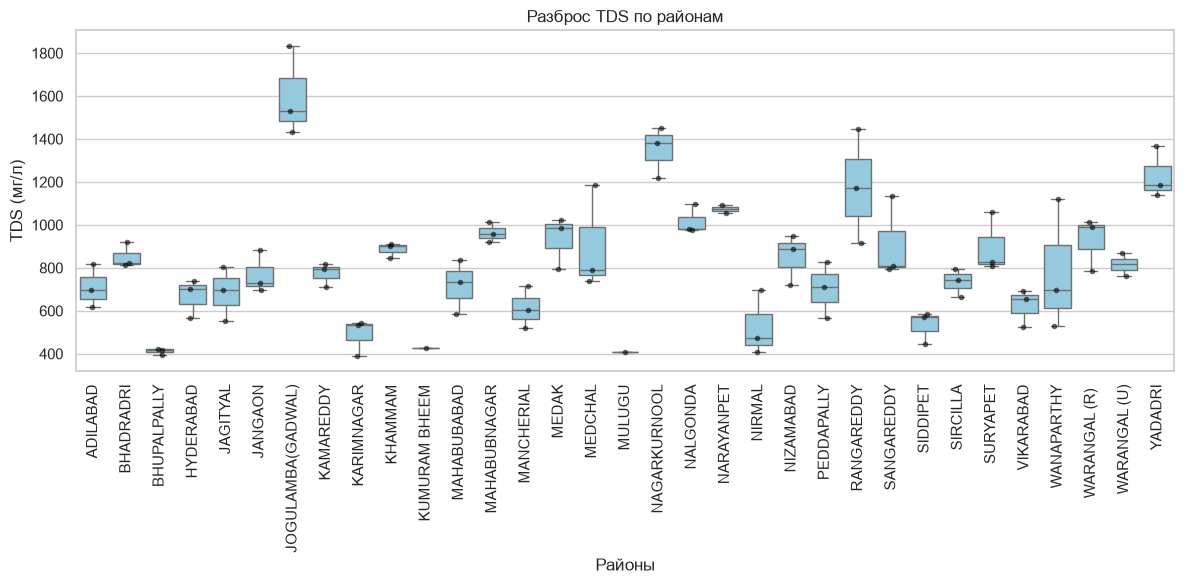

In [118]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=final_data, 
    x='district', 
    y='TDS', 
    color='skyblue', 
    showfliers=False 
)

sns.stripplot(
    data=final_data, 
    x='district', 
    y='TDS', 
    color='black', 
    size=4, 
    alpha=0.6,
)

plt.title('Разброс TDS по районам')
plt.xticks(rotation=90)
plt.xlabel('Районы')
plt.ylabel('TDS (мг/л)')
plt.tight_layout()
plt.show()

Уравнение регрессии: TDS = 0.6400 * E.C + -0.0000
Коэффициент детерминации R^2 = 1.00000


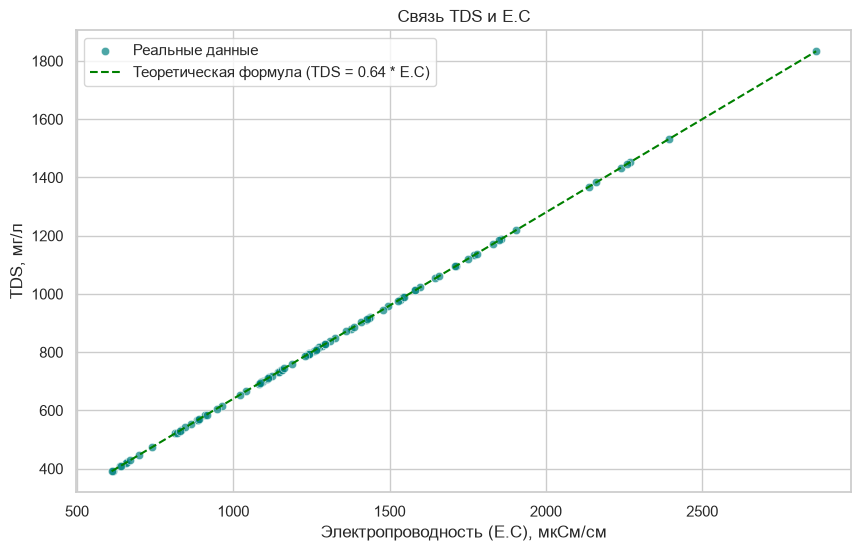

In [134]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

plt.figure()
sns.scatterplot(data=final_data, x='E.C', y='TDS', alpha=0.7, color='teal', label='Реальные данные')

x_vals = np.linspace(final_data['E.C'].min(), final_data['E.C'].max(), 100)
plt.plot(x_vals, 0.64 * x_vals, color='green', linestyle='--', label='Теоретическая формула (TDS = 0.64 * E.C)')

print(f"Уравнение регрессии: TDS = {slope:.4f} * E.C + {intercept:.4f}")
print(f"Коэффициент детерминации R^2 = {r_squared:.5f}")

plt.title('Связь TDS и E.C')
plt.xlabel('Электропроводность (E.C), мкСм/см')
plt.ylabel('TDS, мг/л')
plt.legend()
plt.show()

#### 1.2.2 F (Фторид ионы)

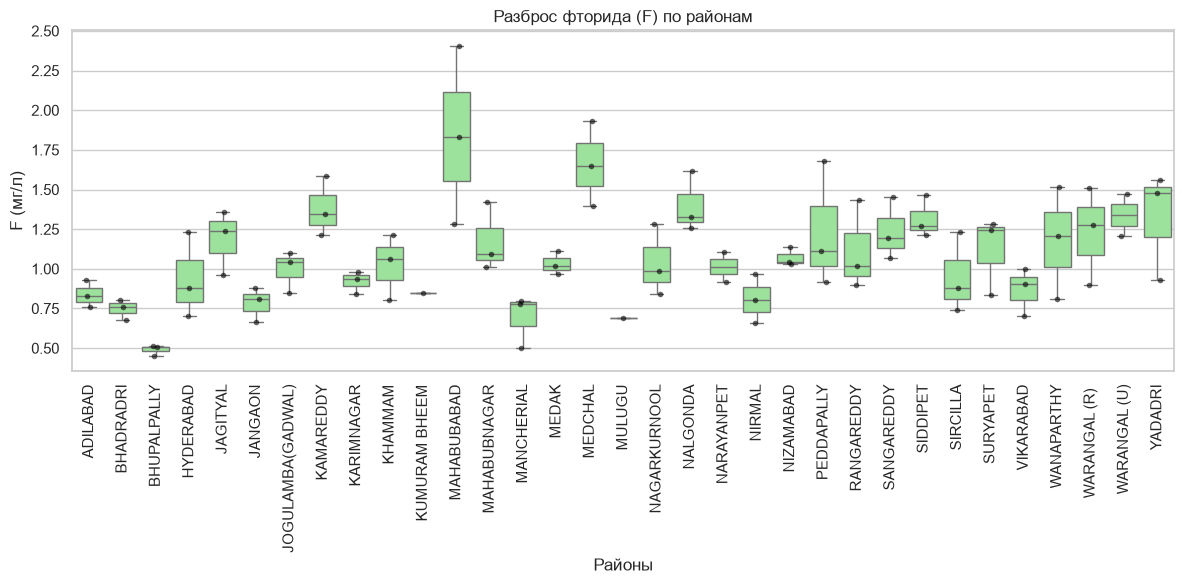

In [119]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=final_data, 
    x='district', 
    y='F', 
    color='lightgreen', 
    showfliers=False
)

sns.stripplot(
    data=final_data, 
    x='district', 
    y='F', 
    color='black', 
    size=4, 
    alpha=0.6, 
    jitter=True
)

plt.title('Разброс фторида (F) по районам')
plt.xticks(rotation=90)
plt.xlabel('Районы')
plt.ylabel('F (мг/л)')
plt.tight_layout()
plt.show()

#### 1.2.3 Rainfall (Осадки)

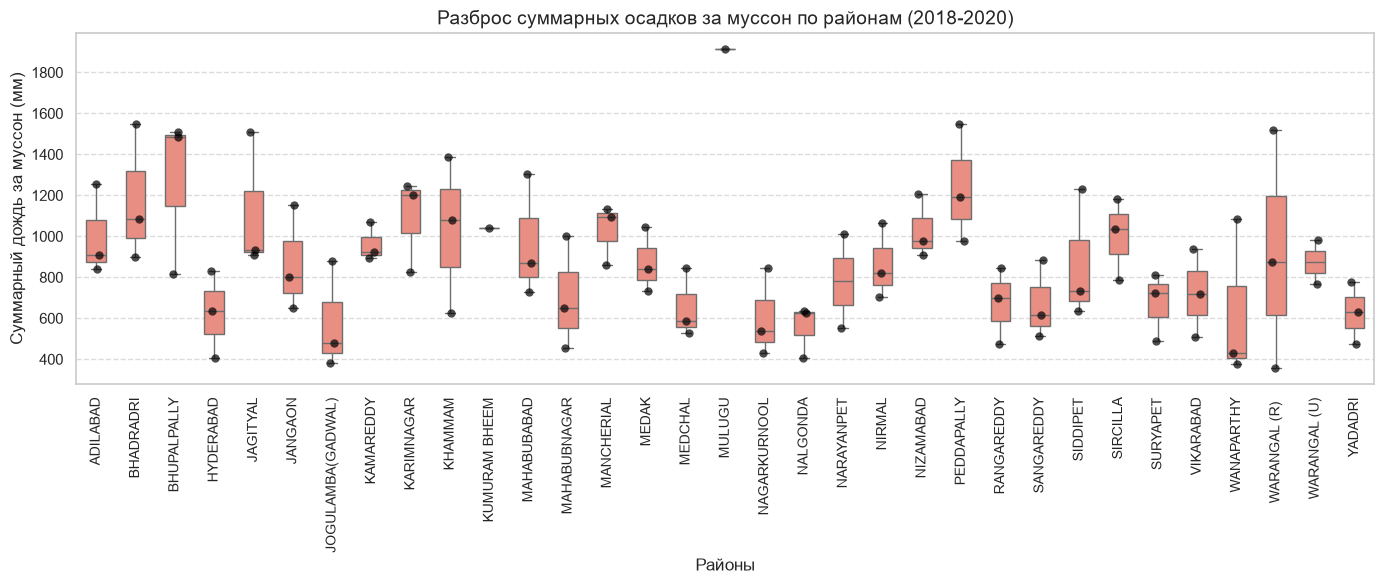

In [133]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=final_data, 
    x='district', 
    y='total_rainfall_mm', 
    color='salmon', 
    width=0.5,
    showfliers=False 
)

sns.stripplot(
    data=final_data, 
    x='district', 
    y='total_rainfall_mm', 
    color='black', 
    size=6, 
    alpha=0.7
)

plt.title('Разброс суммарных осадков за муссон по районам (2018-2020)', fontsize=14)
plt.xlabel('Районы', fontsize=12)
plt.ylabel('Суммарный дождь за муссон (мм)', fontsize=12)

plt.xticks(rotation=90, fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### <a id="section1_1"></a>1.3 Исследование зависимостей
#### 1.3.1 Величины одной природы TDS и F

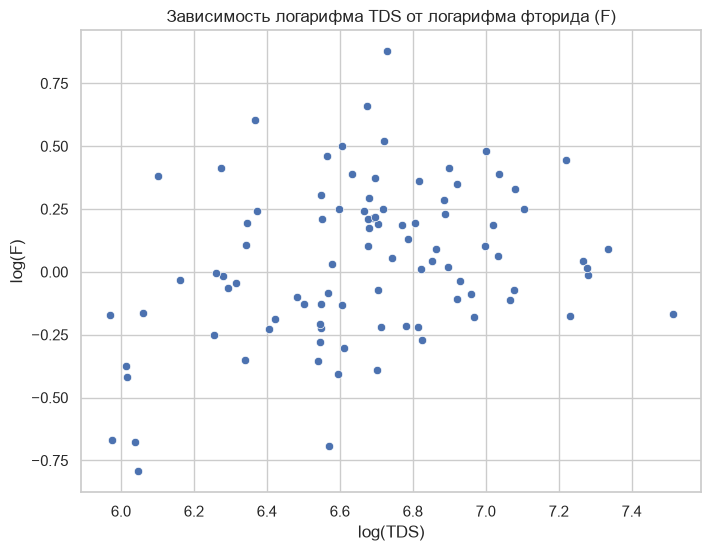

Коэффициент Пирсона: 0.177 (p-value: 0.090)
Коэффициент Спирмена: 0.288 (p-value: 0.005)


In [108]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

plt.figure(figsize=(8, 6))
sns.scatterplot(data=final_data, x=np.log(final_data['TDS']), y=np.log(final_data['F']))
plt.title('Зависимость логарифма TDS от логарифма фторида (F)')
plt.xlabel('log(TDS)')
plt.ylabel('log(F)')
plt.grid(True)
plt.show()

pearson_corr, pearson_p = stats.pearsonr(final_data['TDS'], final_data['F'])
spearman_corr, spearman_p = stats.spearmanr(final_data['TDS'], final_data['F'])

print(f"Коэффициент Пирсона: {pearson_corr:.3f} (p-value: {pearson_p:.3f})")
print(f"Коэффициент Спирмена: {spearman_corr:.3f} (p-value: {spearman_p:.3f})")

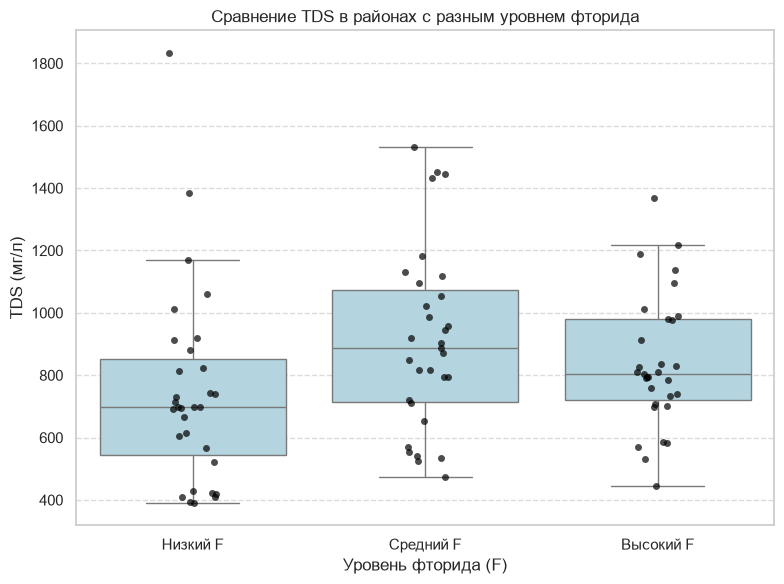

In [120]:
final_data['F_group'] = pd.qcut(final_data['F'], q=3, labels=['Низкий F', 'Средний F', 'Высокий F'])

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=final_data, 
    x='F_group', 
    y='TDS', 
    color='lightblue', 
    showfliers=False
)

sns.stripplot(
    data=final_data, 
    x='F_group', 
    y='TDS', 
    color='black', 
    size=5, 
    alpha=0.7
)

plt.title('Сравнение TDS в районах с разным уровнем фторида')
plt.xlabel('Уровень фторида (F)')
plt.ylabel('TDS (мг/л)')
plt.grid(True, axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [110]:
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(final_data['F_group'], pd.qcut(final_data['TDS'], q=3))

chi2, p_val, dof, expected = chi2_contingency(contingency_table)

print(f"Статистика Хи-квадрат: {chi2:.3f}")
print(f"p-value: {p_val:.3f}")

Статистика Хи-квадрат: 11.226
p-value: 0.024


#### 1.3.2 Геохимическая связь Ca и F

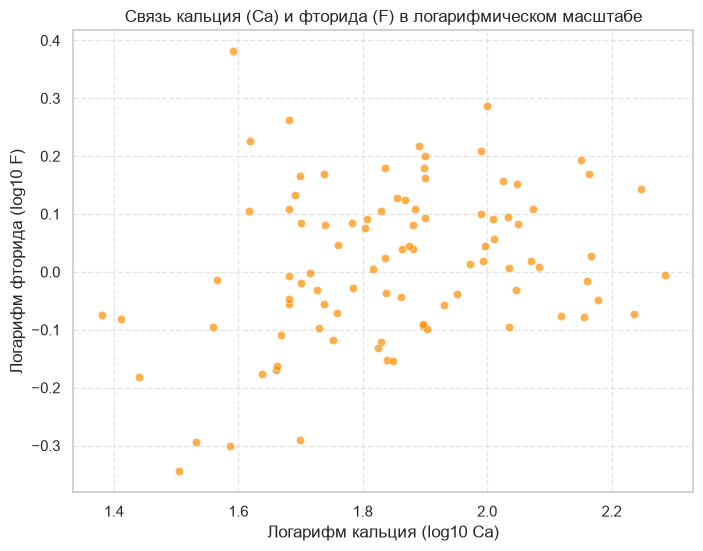

Корреляция Пирсона: 0.285 (p-value: 0.0056)
Корреляция Спирмена: 0.278 (p-value: 0.0070)


In [132]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

final_data['log_Ca'] = np.log10(final_data['Ca'])
final_data['log_F'] = np.log10(final_data['F'])

plt.figure(figsize=(8, 6))

sns.scatterplot(data=final_data, x='log_Ca', y='log_F', alpha=0.7, color='darkorange')

plt.title('Связь кальция (Ca) и фторида (F) в логарифмическом масштабе')
plt.xlabel('Логарифм кальция (log10 Ca)')
plt.ylabel('Логарифм фторида (log10 F)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

pearson_corr, p_value_p = pearsonr(final_data['log_Ca'], final_data['log_F'])
spearman_corr, p_value_s = spearmanr(final_data['log_Ca'], final_data['log_F'])

print(f"Корреляция Пирсона: {pearson_corr:.3f} (p-value: {p_value_p:.4f})")
print(f"Корреляция Спирмена: {spearman_corr:.3f} (p-value: {p_value_s:.4f})")

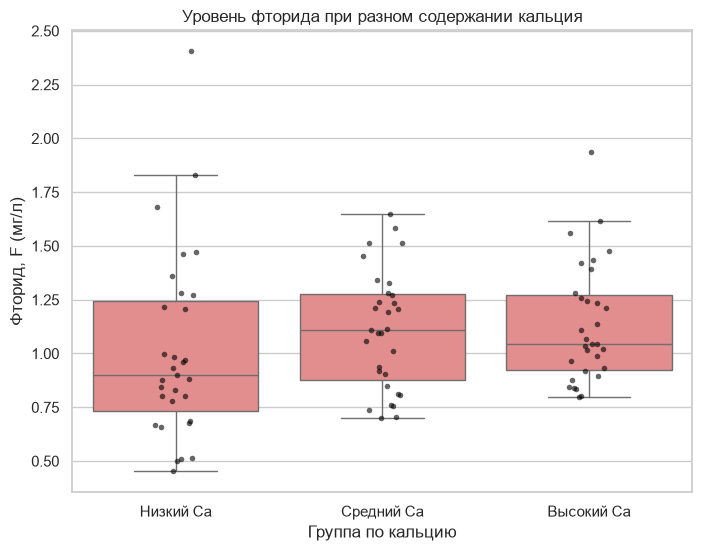

In [131]:
final_data['Ca_group'] = pd.qcut(final_data['Ca'], q=3, labels=['Низкий Ca', 'Средний Ca', 'Высокий Ca'])

plt.figure(figsize=(8, 6))
sns.boxplot(data=final_data, x='Ca_group', y='F', color='lightcoral', showfliers=False)
sns.stripplot(data=final_data, x='Ca_group', y='F', color='black', size=4, alpha=0.6, jitter=True)

plt.title('Уровень фторида при разном содержании кальция')
plt.xlabel('Группа по кальцию')
plt.ylabel('Фторид, F (мг/л)')
plt.show()

### <a id="section1_1"></a>1.4 Состоятельность оценок
#### 1.4.1 TDS (Общее содержание солей)

In [142]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

def simulate_lln(data_col, name, color="blue", num_simulations=1000):
    true_mean = data_col.mean()

    n_values = [2, 5, 10, 20, 30, 50, 70, 90, 110, 150, 200]
    
    results = []
    
    for n in n_values:
        samples = np.random.choice(data_col, size=(num_simulations, n), replace=True)
        sample_means = np.mean(samples, axis=1)
        for mean in sample_means:
            results.append({'n': n, 'mean': mean})
            
    df_results = pd.DataFrame(results)

    plt.figure(figsize=(12, 6))

    sns.scatterplot(
        data=df_results, 
        x='n', 
        y='mean', 
        alpha=0.15,
        color=color, 
        s=20,  
        edgecolor=None
    )
    
    plt.axhline(y=true_mean, color='red', linestyle='--', linewidth=2, 
                label=f'Генеральное среднее: {true_mean:.2f}')

    plt.title(f'Демонстрация состоятельности оценки (ЗБЧ) для {name}', fontsize=16, pad=15)
    plt.xlabel('Объем выборки (n)', fontsize=14)
    plt.ylabel(f'Выборочное среднее ({name})', fontsize=14)
    
    plt.axvline(x=93, color='gray', linestyle=':', linewidth=2, label='N = 93 (размер генеральной совокупности)')
    
    plt.legend(loc='upper right', fontsize=12)
    plt.tight_layout()
    plt.show()

print("Готово")

Готово


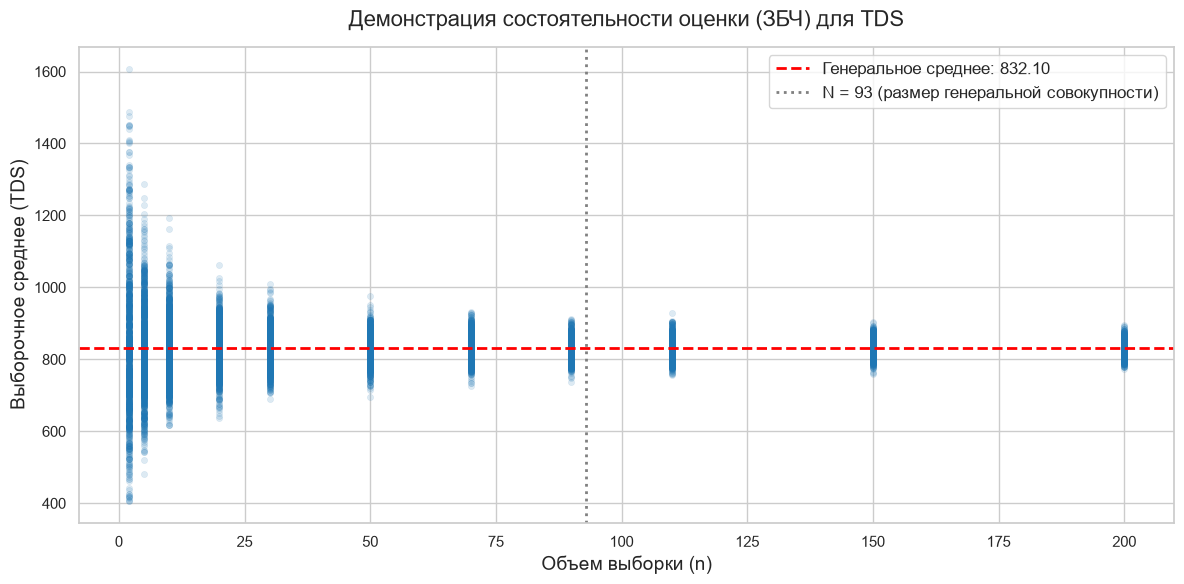

In [137]:
simulate_lln(final_data['TDS'], name='TDS', color='#1f77b4')

#### 1.4.2 F (Фторид ионы)

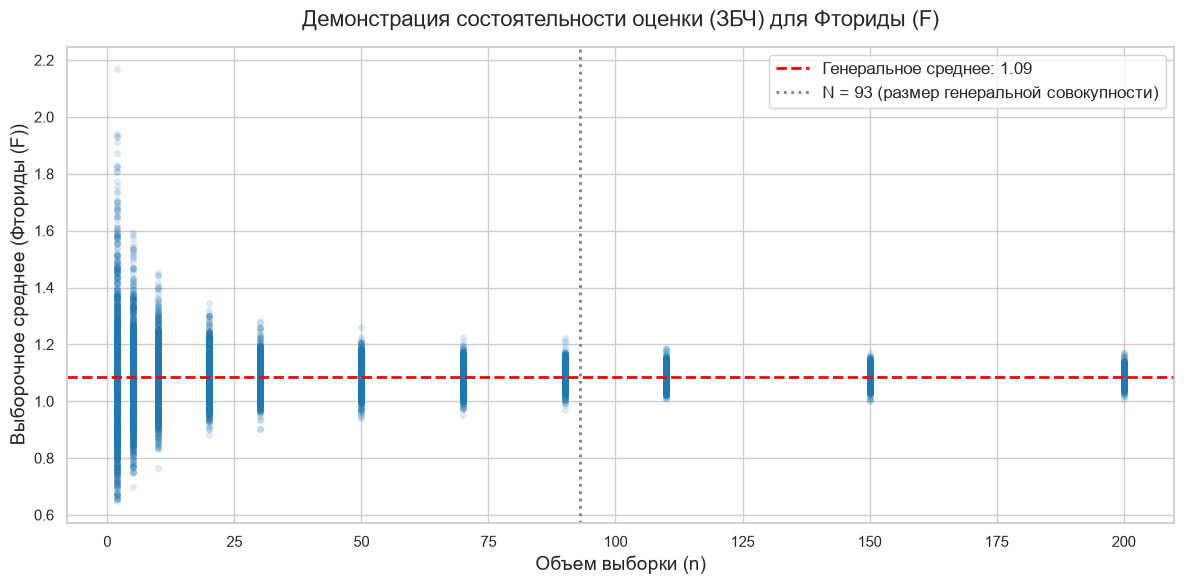

In [140]:
simulate_lln(final_data['F'], name='Фториды (F)', color='#1f77b4')

#### 1.2.3 Rainfall (Осадки)

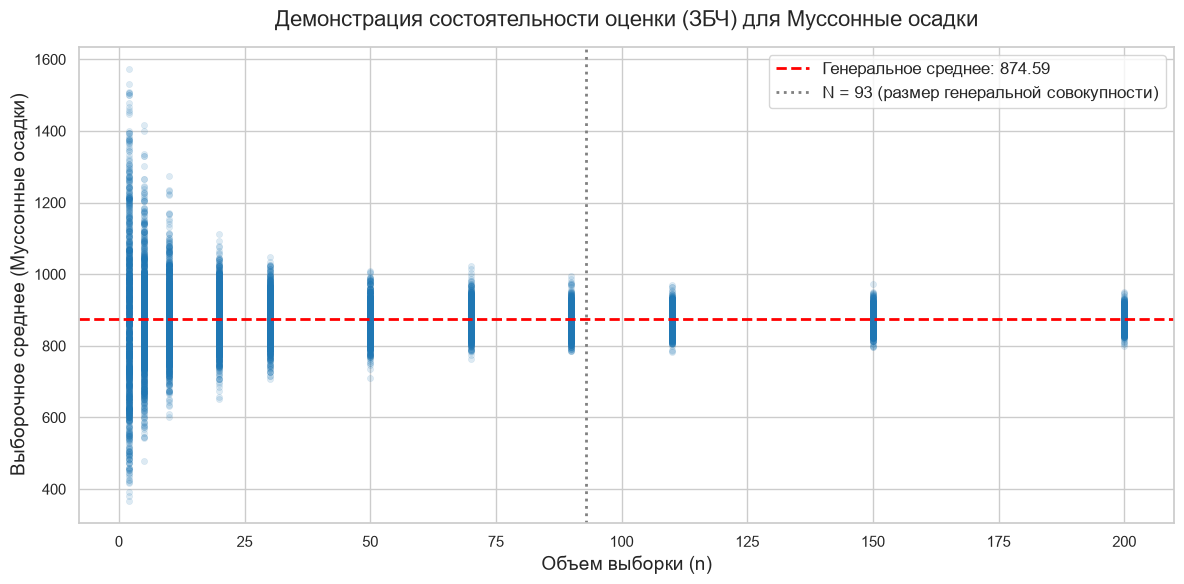

In [141]:
simulate_lln(final_data['total_rainfall_mm'], name='Муссонные осадки', color='#1f77b4')

### <a id="section1_1"></a>1.5 Приведение к стандартному нормальному
#### 1.5.1 TDS (Общее содержание солей)

#### 1.5.2 F (Фторид ионы)